[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch38_LabCh38_Scaling_In_Miniature.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 38: Pretraining at Scale** (Part VIII: Language Models).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=38](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=38)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* The simplified video course for kids: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch38 - Scaling in Miniature
## Nine small language models, three widths by three corpus sizes, and the two curves that scaling studies draw

This lab goes with **Chapter 38** of *The Why Book of Deep Learning, Part 2*.

Chapter 38 is about what happens when next-token prediction is done with a very large model on a very large
part of the written record. Nobody can run that on a laptop. What you can run is the *experiment design* that
the scaling studies used: train the same model at several sizes, on several amounts of text, hold everything
else fixed, and plot the validation loss. Here the model is TinyGPT from Chapter 35 at three widths, the text
is IMDB reviews at three sizes, and each of the nine runs lasts a few hundred steps.

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Count a model family's parameters from one formula and check each against Keras | Step 4 |
| Measure a run in tokens seen, passes over the corpus, tokens per parameter and compute | Steps 5 and 6 |
| Time one run and budget a grid before starting it | Step 7 |
| Read a grid of losses as two curves: loss against data, loss against parameters | Steps 9 to 11 |
| Tell an overfitting corner from an underfitting corner by the train/validation gap | Step 12 |
| Say why a slope fitted to three points is not a scaling law | Step 13 |
| Catch a model reciting its training text | Step 14 |
| Do the memory arithmetic for training: four copies of the weights | Step 15 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** about four to five minutes on a laptop CPU, nearly all of it in Steps 7 and 8. No GPU is
> needed. The only download is the IMDB data set that ships with Keras (`keras.datasets.imdb`).

> **Honest scale:** this is a miniature of a miniature. The largest model here has about a hundred thousand
> parameters and each run reads about 1.6 million characters; the studies in the chapter span models up to
> billions of parameters and hundreds of billions of tokens. Each run here is also stopped long before the
> model has finished learning. The lab shows the *shape* of the questions, the two failure corners, and how
> to measure them. It does not reproduce anybody's scaling law, and its numbers say nothing about what a
> full-size model achieves.

---
## Step 1 - Imports and one seed

In [1]:
import os, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 38
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.1


---
## Step 2 - The corpus and the tokenizer, exactly as in Chapter 35

`load_corpus()`, `encode()` and `decode()` are copied word for word from the Chapter 35 lab: 3,000 IMDB
reviews decoded back to lowercase text, one character per token, a vocabulary of 39 characters. The first 90%
of the reviews are for training and the last 10% for validation, split **by review**.

Notice what is missing: labels. IMDB comes with a sentiment label for every review and we throw it away. The
text is its own answer key. That is **self-supervision**, and it is why the supply of training data for a
language model is, in principle, everything ever written.

> **Predict:** roughly how many characters is the training text? (Chapter 35: 3,000 reviews, about 1,300
> characters each, nine tenths of them.)

In [2]:
ALPHABET = "\n '0123456789abcdefghijklmnopqrstuvwxyz"   # newline, space, apostrophe, digits, letters


def load_corpus(n_reviews=3000):
    """IMDB reviews from keras.datasets, decoded to lowercase text. Returns a list of strings, one per review.
    Only the characters in ALPHABET survive; everything else is dropped."""
    (x_train, _), _ = keras.datasets.imdb.load_data()
    word_index = keras.datasets.imdb.get_word_index()
    id_to_word = {i + 3: w for w, i in word_index.items()}      # ids 0, 1, 2 are pad, start, unknown
    keep = set(ALPHABET) - {"\n"}
    reviews = []
    for ids in x_train[:n_reviews]:
        words = [id_to_word.get(i, "") for i in ids if i >= 3]
        line = " ".join(w for w in words if w and w != "br").lower()
        line = "".join(ch for ch in line if ch in keep)
        reviews.append(" ".join(line.split()))
    return reviews


V = len(ALPHABET)
char_to_id = {ch: i for i, ch in enumerate(ALPHABET)}


def encode(text):
    """text -> array of ids. Characters outside ALPHABET are dropped."""
    return np.array([char_to_id[ch] for ch in text.lower() if ch in char_to_id], dtype=np.int32)


def decode(ids):
    """ids -> text."""
    return "".join(ALPHABET[int(i)] for i in ids)


reviews = load_corpus()
n_train_reviews = int(len(reviews) * 0.9)
train_ids = encode("\n".join(reviews[:n_train_reviews]) + "\n")
val_ids = encode("\n".join(reviews[n_train_reviews:]) + "\n")
print(f"V = {V} characters")
print(f"train: {len(train_ids):,} characters   validation: {len(val_ids):,} characters")
print(repr(decode(train_ids[:90])), "...")

V = 39 characters
train: 3,500,601 characters   validation: 393,306 characters
"this film was just brilliant casting location scenery story direction everyone's really su" ...


---
## Step 3 - Windows, a fixed validation set, and the rungs to beat

`random_windows()` is also Chapter 35's: windows of 64 characters starting at random places, with the target
equal to the input shifted by one. Every model in this lab is scored on the **same** 1,000 validation windows
(64,000 next-character questions), drawn once from reviews that no model trains on.

We also recompute Chapter 35's three rungs, because a loss means little without them: a blind guess (ln V),
a table of letter frequencies (no context), and a bigram table (one character of context).

> **Predict:** ln 39 to two decimals. Which rung do you expect a 400-step model to reach?

In [3]:
CONTEXT = 64


def random_windows(data, n, context=CONTEXT, rng=rng):
    """n windows starting at random places in data. Returns x (n, context) and y (n, context), y = x shifted by one."""
    starts = rng.integers(0, len(data) - context - 1, size=n)
    idx = starts[:, None] + np.arange(context + 1)[None, :]
    w = data[idx]
    return w[:, :-1], w[:, 1:]


x_val, y_val = random_windows(val_ids, 1000, rng=np.random.default_rng(1))     # one fixed validation set
print("fixed validation set:", x_val.shape, "=", f"{y_val.size:,}", "questions")

loss_blind = float(np.log(V))
counts = np.bincount(train_ids, minlength=V).astype(np.float64)
p_uni = counts / counts.sum()
loss_unigram = float(-np.log(p_uni[val_ids]).mean())
pair = np.zeros((V, V))
np.add.at(pair, (train_ids[:-1], train_ids[1:]), 1)
p_bi = (pair + 0.01) / (pair + 0.01).sum(axis=1, keepdims=True)     # 0.01 keeps unseen pairs off zero
loss_bigram = float(-np.log(p_bi[val_ids[:-1], val_ids[1:]]).mean())
print(f"blind guess        ln {V} = {loss_blind:.3f}")
print(f"letter frequencies       = {loss_unigram:.3f}")
print(f"bigram table             = {loss_bigram:.3f}")

fixed validation set: (1000, 64) = 64,000 questions


blind guess        ln 39 = 3.664
letter frequencies       = 2.883
bigram table             = 2.352


---
## Step 4 - One model family, three sizes

A scaling study needs a **family**: one design with a dial. Ours is TinyGPT with the width d on the dial.
Everything else stays as Chapter 35 set it: 2 pre-norm blocks, 4 heads, context 64, learnt positions, untied
head. The feed-forward layer stays four times the width, as it is in TinyGPT (256 = 4 × 64) and in GPT-2.

The parameter formula is Chapter 35's:

* token table V·d, position table T·d
* each block: attention 4d² + 4d, feed-forward (d·ff + ff) + (ff·d + d), two LayerNorms 4d
* final LayerNorm 2d, head d·V + V

`TokenAndPosition` and `build_tinygpt()` are copied word for word from the Chapter 35 lab.

> **Predict:** halving d from 64 to 32 divides the parameter count by about what? (Look at which terms have a
> d² in them.) Then predict it for 16.

In [4]:
def count_tinygpt(vocab_size, d=64, heads=4, blocks=2, ff=256, context=64):
    """The hand count. heads does not appear: splitting d into heads moves no weights."""
    token_table = vocab_size * d
    position_table = context * d
    attention = 4 * d * d + 4 * d
    feed_forward = (d * ff + ff) + (ff * d + d)
    norms = 2 * (2 * d)
    one_block = attention + feed_forward + norms
    final_norm = 2 * d
    head = d * vocab_size + vocab_size
    parts = {"token table": token_table, "position table": position_table,
             "blocks": blocks * one_block, "final norm": final_norm, "head": head}
    return parts, one_block, attention, feed_forward


class TokenAndPosition(layers.Layer):
    """ids (batch, T) -> vectors (batch, T, d): a token table plus a learnt position table."""

    def __init__(self, vocab_size, context, d, **kwargs):
        super().__init__(**kwargs)
        init = keras.initializers.RandomNormal(stddev=0.02)
        self.token_table = layers.Embedding(vocab_size, d, embeddings_initializer=init, name="token_table")
        self.position_table = layers.Embedding(context, d, embeddings_initializer=init, name="position_table")

    def call(self, ids):
        positions = keras.ops.arange(keras.ops.shape(ids)[1])
        return self.token_table(ids) + self.position_table(positions)


def build_tinygpt(vocab_size, d=64, heads=4, blocks=2, ff=256, context=64, dropout=0.0, causal=True):
    """TinyGPT: decoder-only, pre-norm, learnt positions, untied head. ids (batch, context) -> logits (batch, context, vocab_size).
    causal=False removes the mask (only to show what goes wrong). Needs the TokenAndPosition layer above."""
    ids = layers.Input(shape=(context,), dtype="int32", name="ids")
    x = TokenAndPosition(vocab_size, context, d, name="embed")(ids)
    for b in range(1, blocks + 1):
        h = layers.LayerNormalization(epsilon=1e-5, name=f"block{b}_norm1")(x)
        h = layers.MultiHeadAttention(num_heads=heads, key_dim=d // heads, dropout=dropout,
                                      name=f"block{b}_attention")(h, h, use_causal_mask=causal)
        x = layers.Add(name=f"block{b}_add1")([x, h])
        h = layers.LayerNormalization(epsilon=1e-5, name=f"block{b}_norm2")(x)
        h = layers.Dense(ff, activation="gelu", name=f"block{b}_ff_wide")(h)
        h = layers.Dense(d, name=f"block{b}_ff_narrow")(h)
        if dropout > 0:
            h = layers.Dropout(dropout, name=f"block{b}_dropout")(h)
        x = layers.Add(name=f"block{b}_add2")([x, h])
    x = layers.LayerNormalization(epsilon=1e-5, name="final_norm")(x)
    logits = layers.Dense(vocab_size, kernel_initializer=keras.initializers.RandomNormal(stddev=0.02), name="head")(x)
    return keras.Model(ids, logits, name="TinyGPT")


WIDTHS = [16, 32, 64]
n_params = {}
print(f"{'width d':>8s} {'ff':>5s} {'one block':>10s} {'hand count':>11s} {'Keras':>9s}   share in blocks")
for d in WIDTHS:
    parts, one_block, _, _ = count_tinygpt(V, d=d, ff=4 * d)
    hand = sum(parts.values())
    m = build_tinygpt(V, d=d, ff=4 * d)
    assert m.count_params() == hand
    n_params[d] = hand
    print(f"{d:8d} {4 * d:5d} {one_block:10,d} {hand:11,d} {m.count_params():9,d}   {parts['blocks'] / hand:6.1%}")
assert n_params[64] == 109_223
print(f"\nd = 64 is Chapter 35's TinyGPT. It is {n_params[64] / n_params[32]:.2f} times the d = 32 model "
      f"and {n_params[64] / n_params[16]:.2f} times the d = 16 model.")
probe = build_tinygpt(V, d=16, ff=64)
print("shapes for d = 16: ids", x_val[:4].shape, "-> logits", tuple(probe(x_val[:4]).shape))

 width d    ff  one block  hand count     Keras   share in blocks


      16    64      3,280       8,903     8,903    73.7%


      32   128     12,704      30,055    30,055    84.5%


      64   256     49,984     109,223   109,223    91.5%

d = 64 is Chapter 35's TinyGPT. It is 3.63 times the d = 32 model and 12.27 times the d = 16 model.


shapes for d = 16: ids (4, 64) -> logits (4, 64, 39)


### Why we see this

The blocks hold most of the weights and every term in a block that matters is a d². So doubling the width
nearly quadruples the model: not quite, because the tables and the head grow only in proportion to d. From
d = 16 to d = 64 the width grows 4 times and the parameter count about 12 times. Width is a coarse dial.
Real families also turn depth, and Trial 4 lets you try that.

---
## Step 5 - Three sizes of corpus

The other axis is the amount of text. All three corpora are **prefixes** of the same training text, so the
small ones are contained in the large one and nothing differs but the amount:

* **tiny:** the first 2,000 characters (the size of Chapter 35's memorising experiment: a review or two)
* **middle:** the first 80,000 characters (about 70 reviews)
* **full:** all of the training text (2,700 reviews)

Each is about 40 times the one before, so they sit evenly spaced on a logarithmic axis.

> **Predict:** will the loss improve by the same amount at each of the two jumps?

In [5]:
CORPUS = {"2,000": 2_000, "80,000": 80_000, "full": len(train_ids)}
for name, n in CORPUS.items():
    print(f"{name:>8s}: {n:>9,} characters   ends with {decode(train_ids[n - 40:n])!r}")
print(f"\nratios: {80_000 / 2_000:.0f} times, then {len(train_ids) / 80_000:.1f} times")

   2,000:     2,000 characters   ends with ' for bereavement all joking aside this i'
  80,000:    80,000 characters   ends with "ance's infamous tag lines wendy i'm home"
    full: 3,500,601 characters   ends with 'e all by herself score eight out of ten\n'

ratios: 40 times, then 43.8 times


---
## Step 6 - The budget: what one run costs, in four currencies

Every run gets the same recipe: **400 steps**, batch 64, AdamW, a 40-step warm-up then cosine decay, clipping
at norm 1 (Chapters 8 and 9). So every run answers the same number of next-character questions. What differs
from cell to cell is how that budget meets the model and the text. Four ways to measure it:

* **tokens seen** = steps × batch × context. The same for all nine runs.
* **passes** = tokens seen ÷ corpus size. How many times the run reads its text.
* **tokens per parameter** = tokens seen ÷ parameters. The ratio the Chinchilla study (Hoffmann et al., 2022)
  tuned; in their study the best value was roughly 20.
* **compute** ≈ 6 × parameters × tokens seen floating-point operations: the rule of thumb for transformers
  used by Kaplan et al. (2020). Roughly 2 per weight per token going forward and 4 coming back.

> **Predict:** how many passes does a run make over the 2,000-character corpus? Over the full one? And which
> width is closest to 20 tokens per parameter?

In [6]:
STEPS, BATCH, PEAK_LR, WARMUP = 400, 64, 3e-3, 40
tokens_seen = STEPS * BATCH * CONTEXT
print(f"tokens seen per run: {STEPS} x {BATCH} x {CONTEXT} = {tokens_seen:,}\n")
print("passes over the corpus:")
for name, n in CORPUS.items():
    print(f"  {name:>8s}: {tokens_seen / n:8.2f}")
print("\ntokens seen per parameter, and compute (6 x parameters x tokens):")
for d in WIDTHS:
    print(f"  d = {d:2d}: {n_params[d]:7,d} parameters   {tokens_seen / n_params[d]:6.1f} tokens per parameter"
          f"   {6 * n_params[d] * tokens_seen:.2e} operations")
print("\ncharacters of corpus per parameter (how much text there is to learn from, per weight):")
print(f"  {'':8s}" + "".join(f"{name:>10s}" for name in CORPUS))
for d in WIDTHS:
    print(f"  d = {d:2d}  " + "".join(f"{n / n_params[d]:10.3f}" for n in CORPUS.values()))

tokens seen per run: 400 x 64 x 64 = 1,638,400

passes over the corpus:
     2,000:   819.20
    80,000:    20.48
      full:     0.47

tokens seen per parameter, and compute (6 x parameters x tokens):
  d = 16:   8,903 parameters    184.0 tokens per parameter   8.75e+10 operations
  d = 32:  30,055 parameters     54.5 tokens per parameter   2.95e+11 operations
  d = 64: 109,223 parameters     15.0 tokens per parameter   1.07e+12 operations

characters of corpus per parameter (how much text there is to learn from, per weight):
               2,000    80,000      full
  d = 16       0.225     8.986   393.193
  d = 32       0.067     2.662   116.473
  d = 64       0.018     0.732    32.050


### Why we see this

The full corpus is read less than half of once: nearly every window is new, which is how large models are
pretrained (about one pass, most text seen once). The tiny corpus is read about 800 times. Same number of
gradient steps, a completely different experience.

The last table is the one to keep in mind for the corners of the grid. In the bottom-left cell the model has
more than 50 weights for every character it will ever see. In the top-right cell there are several hundred
characters for every weight.

---
## Step 7 - Time one run before starting nine

Nine runs must share about four minutes. Before launching a grid, time **one** cell and multiply. We time the
most expensive one: the widest model on the full corpus.

Three small functions do the work:

* `new_model(d)` builds and compiles a TinyGPT of width d and keeps a copy of its starting weights.
* `rewind(d)` puts that model back to its starting point: the initial weights, and an optimizer with no
  memory (its running averages and its step counter set to zero). Keras takes several seconds to build the
  training function of a new model, so we build each width once and rewind it between corpora. The three
  runs of one width therefore start from **identical** weights, which is also the fairer experiment.
* `train_cell(d, corpus)` rewinds, trains, and records the training loss (on 500 fresh windows of the run's
  own corpus) and the validation loss.

> **Predict:** d = 64 has 12 times the weights of d = 16. Will it take 12 times as long per step on a CPU?

In [7]:
loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
family, start_weights, trained, results = {}, {}, {}, {}


def new_model(d):
    """Build and compile a TinyGPT of width d with the lab's recipe; remember its starting weights."""
    keras.utils.set_random_seed(SEED)
    model = build_tinygpt(V, d=d, ff=4 * d)
    schedule = keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=0.0, warmup_target=PEAK_LR, warmup_steps=WARMUP,
        decay_steps=STEPS - WARMUP, alpha=0.05)
    model.compile(optimizer=keras.optimizers.AdamW(schedule, weight_decay=0.01, clipnorm=1.0), loss=loss_fn)
    family[d], start_weights[d] = model, model.get_weights()


def rewind(d):
    """Back to the starting line: initial weights, and an optimizer that remembers nothing."""
    family[d].set_weights(start_weights[d])
    for v in family[d].optimizer.variables:                 # Adam's two averages per weight, and the step counter
        v.assign(keras.ops.zeros_like(v))


def train_cell(d, corpus_name):
    """Train TinyGPT of width d on one corpus for STEPS steps, from its starting weights."""
    if d not in family:
        new_model(d)
    rewind(d)
    model, data = family[d], train_ids[:CORPUS[corpus_name]]
    t0 = time.time()
    x, y = random_windows(data, STEPS * BATCH, rng=np.random.default_rng(SEED))
    model.fit(x, y, batch_size=BATCH, epochs=1, shuffle=False, verbose=0)
    seconds = time.time() - t0
    x_tr, y_tr = random_windows(data, 500, rng=np.random.default_rng(2))
    results[(d, corpus_name)] = {"train": model.evaluate(x_tr, y_tr, batch_size=250, verbose=0),
                                 "val": model.evaluate(x_val, y_val, batch_size=250, verbose=0), "seconds": seconds}
    trained[(d, corpus_name)] = model.get_weights()
    return results[(d, corpus_name)]


r = train_cell(64, "full")
print(f"d = 64, full corpus: train {r['train']:.3f}  val {r['val']:.3f}  in {r['seconds']:.0f} s")
print(f"nine runs at this price: about {9 * r['seconds'] / 60:.1f} minutes at most")
print(f"steps taken according to the optimizer: {int(family[64].optimizer.iterations)}")

d = 64, full corpus: train 2.045  val 2.072  in 44 s
nine runs at this price: about 6.7 minutes at most
steps taken according to the optimizer: 400


### Why we see this

One run costs a few tens of seconds at most, so nine fit the budget. The first run of each width is the
slowest, because it includes building the training function. At these sizes the per-step overhead is also as
large as the matrix multiplications, which is why a model with 12 times the weights is nowhere near 12 times
slower here. At full scale it is the other way round: overhead vanishes and cost follows
parameters × tokens closely.

After 400 steps the loss has passed the bigram rung and is still far from the 1.47 that Chapter 35 reached
with 3,000 steps.
**Every model in this grid is stopped early.** Keep that in mind when reading the results.

---
## Step 8 - The other eight runs

> **Predict, and write it down as a 3 × 3 table of guesses before running:** (1) which cell has the lowest
> validation loss? (2) Which has the highest? (3) In which column, if any, does the *smallest* model win?

In [8]:
for d in WIDTHS:
    for name in CORPUS:
        if (d, name) not in results:
            train_cell(d, name)
        r = results[(d, name)]
        print(f"d = {d:2d}  corpus {name:>8s}  train {r['train']:.3f}  val {r['val']:.3f}  gap {r['val'] - r['train']:+.3f}  [{r['seconds']:3.0f} s]")
grid_seconds = sum(r["seconds"] for r in results.values())
print(f"\nnine runs: {grid_seconds:.0f} s of training")

d = 16  corpus    2,000  train 1.847  val 2.695  gap +0.848  [ 18 s]


d = 16  corpus   80,000  train 2.324  val 2.338  gap +0.014  [  9 s]


d = 16  corpus     full  train 2.312  val 2.327  gap +0.016  [  9 s]


d = 32  corpus    2,000  train 0.692  val 3.822  gap +3.129  [ 21 s]


d = 32  corpus   80,000  train 2.212  val 2.239  gap +0.027  [ 11 s]


d = 32  corpus     full  train 2.207  val 2.227  gap +0.020  [ 13 s]


d = 64  corpus    2,000  train 0.131  val 4.989  gap +4.858  [ 22 s]


d = 64  corpus   80,000  train 2.137  val 2.175  gap +0.038  [ 19 s]
d = 64  corpus     full  train 2.045  val 2.072  gap +0.027  [ 44 s]

nine runs: 167 s of training


---
## Step 9 - The grid

Rows are model widths, columns are corpus sizes, and each cell is a validation loss on the same 64,000
questions.

validation loss (nats per character)
                           2,000    80,000      full
d = 16 (  8,903 w)       2.695     2.338     2.327
d = 32 ( 30,055 w)       3.822     2.239     2.227
d = 64 (109,223 w)       4.989     2.175     2.072

rungs: letter frequencies 2.883, bigram table 2.352
best cell : d = 64, corpus full: 2.072
worst cell: d = 64, corpus 2,000: 4.989


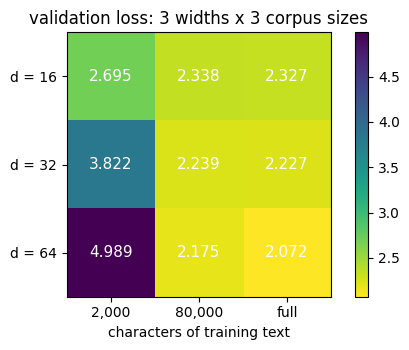

In [9]:
val_grid = np.array([[results[(d, name)]["val"] for name in CORPUS] for d in WIDTHS])
train_grid = np.array([[results[(d, name)]["train"] for name in CORPUS] for d in WIDTHS])

print("validation loss (nats per character)")
print(f"{'':22s}" + "".join(f"{name:>10s}" for name in CORPUS))
for i, d in enumerate(WIDTHS):
    print(f"d = {d:2d} ({n_params[d]:7,d} w)  " + "".join(f"{v:10.3f}" for v in val_grid[i]))
print(f"\nrungs: letter frequencies {loss_unigram:.3f}, bigram table {loss_bigram:.3f}")
bi, bj = np.unravel_index(val_grid.argmin(), val_grid.shape)
wi, wj = np.unravel_index(val_grid.argmax(), val_grid.shape)
print(f"best cell : d = {WIDTHS[bi]}, corpus {list(CORPUS)[bj]}: {val_grid[bi, bj]:.3f}")
print(f"worst cell: d = {WIDTHS[wi]}, corpus {list(CORPUS)[wj]}: {val_grid[wi, wj]:.3f}")

plt.figure(figsize=(5.2, 3.6))
plt.imshow(val_grid, cmap="viridis_r")
plt.xticks(range(3), list(CORPUS)); plt.yticks(range(3), [f"d = {d}" for d in WIDTHS])
for i in range(3):
    for j in range(3):
        plt.text(j, i, f"{val_grid[i, j]:.3f}", ha="center", va="center", color="white", fontsize=11)
plt.xlabel("characters of training text"); plt.title("validation loss: 3 widths x 3 corpus sizes")
plt.colorbar(); plt.tight_layout(); plt.show()

### Why we see this

Read the grid one column at a time. In the **full** column the loss falls as the model widens: a bigger
model, given enough text, predicts better. In the **2,000** column the order turns over: the widest model is
the worst in the whole grid, above even the blind-guess line at 3.664. The middle column has the same order
as the full one, with smaller differences.

---
## Step 10 - Curve one: loss against data, for a fixed model

This is the first picture a scaling study draws. One line per model size; the x-axis is the amount of text,
on a logarithmic scale because the corpus sizes are factors of about 30 apart.

> **Predict:** which line is steepest? Which is flattest between 80,000 characters and the full corpus?

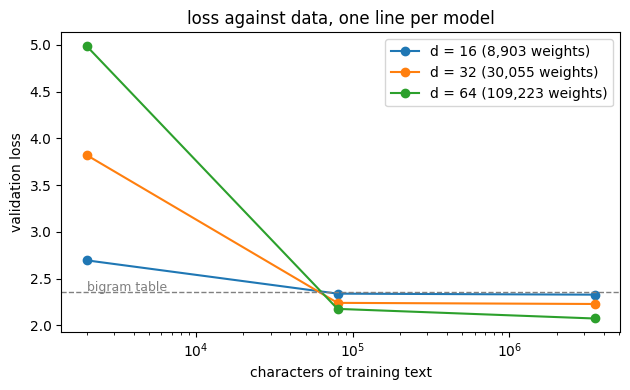

d = 16: 2,000 -> 80,000 changes val by -0.357;  80,000 -> full by -0.011
d = 32: 2,000 -> 80,000 changes val by -1.582;  80,000 -> full by -0.012
d = 64: 2,000 -> 80,000 changes val by -2.814;  80,000 -> full by -0.103


In [10]:
sizes = np.array(list(CORPUS.values()), dtype=float)
plt.figure(figsize=(6.4, 4))
for i, d in enumerate(WIDTHS):
    plt.plot(sizes, val_grid[i], "o-", label=f"d = {d} ({n_params[d]:,} weights)")
plt.axhline(loss_bigram, color="grey", linestyle="--", linewidth=1)
plt.text(sizes[0], loss_bigram + 0.02, "bigram table", fontsize=9, color="grey")
plt.xscale("log"); plt.xlabel("characters of training text"); plt.ylabel("validation loss")
plt.title("loss against data, one line per model"); plt.legend(); plt.tight_layout(); plt.show()

for i, d in enumerate(WIDTHS):
    print(f"d = {d:2d}: 2,000 -> 80,000 changes val by {val_grid[i, 1] - val_grid[i, 0]:+.3f};"
          f"  80,000 -> full by {val_grid[i, 2] - val_grid[i, 1]:+.3f}")

### Why we see this

The first jump in data helps every model, and helps the widest most: it was the most starved.

The second jump, from 80,000 characters to 3.5 million, is a factor of 44, and it does **not** help every
model. The two narrow models gain about a hundredth of a nat. Only the widest gains something you can see.
This is the picture the scaling studies report in the large: a small model follows the curve until it is
full and then goes flat, however much more text it is shown, while a larger model keeps improving.

There is a second reason, and it is a limit of this lab, not a fact about language models. Every run sees
the same 1.6 million characters' worth of windows. On the middle corpus they are about 20 passes over the
same text; on the full corpus they are fresh text. For a model stopped this early, rereading is nearly as
good a lesson as reading on. **Our runs are limited by steps as much as by text.** A real study trains each
point to the same standard before comparing; with a five-minute budget we cannot. We did run the check once
while writing this lab: at 2,000 steps the d = 64 model reaches a validation loss of 1.97 on the
80,000-character corpus, where its training loss (1.13) shows it has begun to memorise, and 1.53 on the full
corpus. With enough steps the gap between the two columns opens wide. Trial 1 lets you watch it start.

---
## Step 11 - Curve two: loss against parameters, for fixed data

The second picture: one line per corpus, the x-axis is the parameter count on a logarithmic scale.

> **Predict:** which line goes down from left to right, and which goes up?

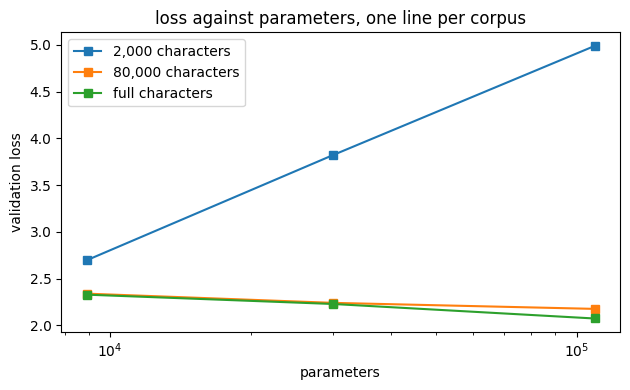

corpus    2,000: best to worst width = [16, 32, 64]
corpus   80,000: best to worst width = [64, 32, 16]
corpus     full: best to worst width = [64, 32, 16]


In [11]:
ps = np.array([n_params[d] for d in WIDTHS], dtype=float)
plt.figure(figsize=(6.4, 4))
for j, name in enumerate(CORPUS):
    plt.plot(ps, val_grid[:, j], "s-", label=f"{name} characters")
plt.xscale("log"); plt.xlabel("parameters"); plt.ylabel("validation loss")
plt.title("loss against parameters, one line per corpus"); plt.legend(); plt.tight_layout(); plt.show()

for j, name in enumerate(CORPUS):
    order = [WIDTHS[i] for i in np.argsort(val_grid[:, j])]
    print(f"corpus {name:>8s}: best to worst width = {order}")

### Why we see this

With enough text, more parameters means lower loss, and the line slopes down. With 2,000 characters the line
slopes **up**: every extra weight is spent on remembering those characters more exactly. "More parameters
always wins" is true only along the lines with enough text. Which line you are on is decided by the data.

---
## Step 12 - The two corners

The validation loss alone cannot tell you *why* a cell is bad. The gap between the training loss (on the
run's own text) and the validation loss can.

> **Predict:** in which cell is the gap largest? In which cells is it about zero?

In [12]:
print("training loss on the run's own corpus")
print(f"{'':10s}" + "".join(f"{name:>10s}" for name in CORPUS))
for i, d in enumerate(WIDTHS):
    print(f"d = {d:2d}    " + "".join(f"{v:10.3f}" for v in train_grid[i]))
print("\ngap = validation - training")
for i, d in enumerate(WIDTHS):
    print(f"d = {d:2d}    " + "".join(f"{v:+10.3f}" for v in (val_grid - train_grid)[i]))

c_over, c_under = results[(64, "2,000")], results[(16, "full")]
print(f"\nsmall-data corner (d = 64, 2,000 characters): train {c_over['train']:.3f}, val {c_over['val']:.3f}"
      f"  -> gap {c_over['val'] - c_over['train']:+.3f}: OVERFITTING")
print(f"small-model corner (d = 16, full corpus):       train {c_under['train']:.3f}, val {c_under['val']:.3f}"
      f"  -> gap {c_under['val'] - c_under['train']:+.3f}: UNDERFITTING")

training loss on the run's own corpus
               2,000    80,000      full
d = 16         1.847     2.324     2.312
d = 32         0.692     2.212     2.207
d = 64         0.131     2.137     2.045

gap = validation - training
d = 16        +0.848    +0.014    +0.016
d = 32        +3.129    +0.027    +0.020
d = 64        +4.858    +0.038    +0.027

small-data corner (d = 64, 2,000 characters): train 0.131, val 4.989  -> gap +4.858: OVERFITTING
small-model corner (d = 16, full corpus):       train 2.312, val 2.327  -> gap +0.016: UNDERFITTING


### Why we see this

Two cells with poor validation loss, for opposite reasons.

* **Small-data corner** (widest model, 2,000 characters): the training loss is far below the validation
  loss. The model fits its own text well and other text badly. More weights or more steps would make this
  worse. More text is the cure.
* **Small-model corner** (narrowest model, full corpus): the two losses are equal. The model is not
  memorising anything; it has not learnt enough. More text will not help, because it has not used up the text
  it has. More weights or more steps would.

Real projects sit somewhere on this grid, and the gap is how you find out where.

---
## Step 13 - A slope through three points is not a law

The scaling studies fit a **power law**: loss ≈ a × (parameters)^(−α), a straight line on log-log axes whose
slope is −α. We can fit one to the full-corpus column. We have three points.

> **Predict:** will the three points lie on a straight line? And if you used the fitted line to predict a
> model with 124 million parameters, would you trust the answer?

In [13]:
log_n, log_l = np.log(ps), np.log(val_grid[:, 2])
slope, intercept = np.polyfit(log_n, log_l, 1)
fitted = np.exp(intercept + slope * log_n)
print(f"fit on the full-corpus column: loss = {np.exp(intercept):.2f} x parameters^({slope:+.3f})")
for d, n, real, fit in zip(WIDTHS, ps, val_grid[:, 2], fitted):
    print(f"  d = {d:2d}  {int(n):7,d} parameters   measured {real:.3f}   line {fit:.3f}")
slope_small = np.polyfit(log_n, np.log(val_grid[:, 0]), 1)[0]
print(f"the same fit on the 2,000-character column gives a slope of {slope_small:+.3f}")
gpt2 = 124_439_808
print(f"\nthe full-corpus line, stretched to {gpt2:,} parameters, says {np.exp(intercept + slope * np.log(gpt2)):.2f}")
print("that number is an artefact of the fit, not a prediction: see below")

fit on the full-corpus column: loss = 3.57 x parameters^(-0.046)
  d = 16    8,903 parameters   measured 2.327   line 2.337
  d = 32   30,055 parameters   measured 2.227   line 2.209
  d = 64  109,223 parameters   measured 2.072   line 2.080
the same fit on the 2,000-character column gives a slope of +0.245

the full-corpus line, stretched to 124,439,808 parameters, says 1.50
that number is an artefact of the fit, not a prediction: see below


### Why we see this

You can always put a line through three points and read off an exponent. This one comes from one seed, one
family, one corpus, and models stopped after 400 steps; change any of those and the slope changes. On the
small corpus the slope even has the opposite sign. And the stretched line carries a 400-step, character-level,
3-megabyte experiment a thousandfold beyond the sizes it was fitted on, to a kind of model, tokenizer and
data it has never seen.

The published scaling laws are worth more because they were fitted over many orders of magnitude, with every
point trained properly, and then **checked by building the next model and seeing where it landed**. Even so
they are empirical regularities for one kind of model on one kind of data, and the exponents differ between
studies. Treat an exponent as a measurement with a context, never as a constant of nature.

---
## Step 14 - Catch a model reciting

The chapter says a language model both generalises and memorises. The small-data corner lets you see
memorising directly. Give the model the first 20 characters of its training text and let it continue,
always taking its most likely next character. Then count how many of the next 60 characters match the
training text exactly. Do the same with the model trained on the full corpus, which met that passage at most
once.

> **Predict:** how many of the 60 will each model reproduce?

In [14]:
def continue_greedy(model, prompt_ids, n_chars=60):
    """Continue a list of ids by n_chars characters, always taking the most likely next one."""
    context = model.input_shape[1]
    ids = list(prompt_ids)
    for _ in range(n_chars):
        recent = ids[-context:]
        buf = np.zeros((1, context), dtype=np.int32)
        buf[0, :len(recent)] = recent                             # filler to the right is invisible
        ids.append(int(model.predict_on_batch(buf)[0, len(recent) - 1].argmax()))
    return np.array(ids[len(prompt_ids):])


prompt, truth = train_ids[:20], train_ids[20:80]
print("prompt             :", repr(decode(prompt)))
print("the training text  :", repr(decode(truth)))
for key, label in [((64, "2,000"), "d = 64 on 2,000    "), ((64, "full"), "d = 64 on the full ")]:
    family[64].set_weights(trained[key])
    out = continue_greedy(family[64], prompt)
    print(f"{label}:", repr(decode(out)), f" {int((out == truth).sum())} of 60 match")

prompt             : 'this film was just b'
the training text  : "rilliant casting location scenery story direction everyone's"


d = 64 on 2,000    : "rilliant casting location scenery story direction everyone's"  60 of 60 match
d = 64 on the full : 'e the the the the the the the the the the the the the the th'  5 of 60 match


### Why we see this

The model trained on 2,000 characters has read this exact passage hundreds of times and gives it back
letter for letter. The model trained on the full corpus met it once at most, among millions of other
characters, and cannot. Asked for its single most likely continuation it falls into "the the the", the
greedy loop of Chapter 36: the commonest word in English, over and over.

Neither is "the" behaviour of language models. Large models do both at once: they generalise from most of
their text, and they can reproduce strings that were repeated many times in it. How often a string appeared
matters more than how big the model is.

---
## Step 15 - The memory bill: four copies

Training needs more memory than the weights. For every weight the optimizer also holds a gradient, and Adam
holds two running averages (Chapter 8): the mean of recent gradients and the mean of their squares. That is
**four numbers per weight** before a single activation is stored.

We can check the claim about Adam on a real Keras optimizer, then do the arithmetic for GPT-2 small (2019)
with Chapter 35's counting function.

> **Predict:** GPT-2 small has 124,439,808 parameters of 4 bytes each. How many gigabytes are four copies?

In [15]:
m = build_tinygpt(V)
opt = keras.optimizers.AdamW(1e-3)
opt.build(m.trainable_variables)
slots = sum(int(np.prod(v.shape)) for v in opt.variables)
print(f"TinyGPT weights: {m.count_params():,}   numbers held by AdamW: {slots:,}   ratio {slots / m.count_params():.3f}")

gpt2_parts, gpt2_block, _, _ = count_tinygpt(50257, d=768, heads=12, blocks=12, ff=3072, context=1024)
gpt2_parts["head"] = 0                                    # GPT-2 ties its head to the token table
gpt2 = sum(gpt2_parts.values())
assert gpt2 == 124_439_808
for name, n in [("TinyGPT", m.count_params()), ("GPT-2 small", gpt2)]:
    one = n * 4
    print(f"{name:12s} {n:>12,} parameters   one copy {one / 1e6:10.2f} MB   four copies {4 * one / 1e9:8.4f} GB")
print(f"\n20 tokens per parameter for GPT-2 small would be {20 * gpt2 / 1e9:.2f} billion tokens")
print(f"20 tokens per parameter for TinyGPT would be {20 * n_params[64]:,} characters = {20 * n_params[64] / (BATCH * CONTEXT):.0f} steps at our batch size")
print(f"GPT-3 (2020): 175 billion parameters, 300 billion training tokens = {300 / 175:.1f} tokens per parameter")
print(f"\nwhole notebook: {time.time() - t_start:.0f} s")

TinyGPT weights: 109,223   numbers held by AdamW: 218,448   ratio 2.000
TinyGPT           109,223 parameters   one copy       0.44 MB   four copies   0.0017 GB
GPT-2 small   124,439,808 parameters   one copy     497.76 MB   four copies   1.9910 GB

20 tokens per parameter for GPT-2 small would be 2.49 billion tokens
20 tokens per parameter for TinyGPT would be 2,184,460 characters = 533 steps at our batch size
GPT-3 (2020): 175 billion parameters, 300 billion training tokens = 1.7 tokens per parameter

whole notebook: 194 s


### Why we see this

AdamW holds two numbers for every weight (plus a step counter and a learning rate), so the ratio is 2 almost
exactly. With the weights and the gradients that makes four. For GPT-2 small that is about 2 GB before any
activations, and the activations (every layer's output for every token of every sequence in the batch, kept
for backpropagation) are usually larger still. This is why a model that fits on a GPU for inference may not
fit for training, and why Chapter 40's adapters, which shrink the optimizer's share, matter.

The last three lines put the "20 tokens per parameter" figure beside real sizes. Do not read our grid as a
test of it: that figure was measured on subword models between tens of millions and billions of parameters,
trained to the end of a schedule.

---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 6: `STEPS = 1200` (the lab then takes about 15 minutes) | Does the full column pull away from the 80,000 column? For which width most? | |
| 2 | Step 5: make the tiny corpus 30,000 characters | Does the widest model still lose its column? | |
| 3 | Step 4: `WIDTHS = [8, 16, 32]` | Parameter counts first, by hand. Does the d = 8 model beat the bigram table? | |
| 4 | Step 7: in `train_cell`, build with `blocks=4` | Which costs more parameters: doubling depth or doubling width? Which helps more here? | |
| 5 | Step 7: in `train_cell`, build with `dropout=0.2` | Which corner improves, which gets worse? | |
| 6 | Step 7: `weight_decay=0.3` | Does it rescue the small-data corner? | |
| 7 | Step 14: prompt with characters 1,000 to 1,020 of the training text | How many of 60 does the 2,000-character model reproduce now? | |
| 8 | Step 7: remove `keras.utils.set_random_seed(SEED)` from `train_cell` and run the grid twice | How much does a cell move between runs? Is any conclusion of Step 9 smaller than that? | |

---
## Exercises

1. **Train to the same standard.** Give each cell its own number of steps: stop when the validation loss has
   not improved for three checks of 100 steps. Redraw both curves. Which conclusions of Steps 10 and 11
   survive, and which were artefacts of the fixed budget?
2. **Fixed compute.** Give every width the same budget of 6 × parameters × tokens instead of the same number
   of steps (the narrow models then train for longer). Which width wins on the full corpus now? This is the
   question the Chinchilla study asked.
3. **Error bars.** Run the full-corpus column with three seeds. Report the mean and the spread per width.
   Is the difference between d = 32 and d = 64 larger than the spread?
4. **Duplicates.** Build a corpus of 80,000 characters in which one 200-character passage is repeated 50
   times. Train d = 64 on it and run Step 14 on that passage and on one that appears once. What does this say
   about why pretraining corpora are deduplicated?
5. **Loss per character class.** Split the validation loss of the best model into "inside a word" and "first
   letter of a word". Which is harder, and what would a model need to know to do better at it?
6. **Count the compute of a real model.** With the rule 6 × parameters × tokens, estimate the operations to
   train GPT-2 small at 20 tokens per parameter. Divide by the operations per second your laptop managed in
   Step 7 (work it out from the timing). How many years?

---
## Cheat sheet

| Fact | Value / rule |
|---|---|
| Self-supervision | the target is the input shifted by one: no labels, so any text is training data |
| A model family | one design with a size dial; here TinyGPT with d = 16, 32, 64 and ff = 4d |
| Parameters | V·d + T·d + blocks·(4d² + 4d + 2·d·ff + ff + d + 4d) + 2d + (d·V + V); doubling d nearly quadruples it |
| Tokens seen | steps × batch × context |
| Passes (epochs) | tokens seen ÷ corpus size; large models are pretrained for about one |
| Tokens per parameter | tokens seen ÷ parameters; roughly 20 was best in the Chinchilla study (2022) |
| Compute | ≈ 6 × parameters × tokens floating-point operations |
| Curve one | validation loss against data (log), one line per model size |
| Curve two | validation loss against parameters (log), one line per corpus size |
| Small-data corner | big model, little text: train far below validation: overfitting; cure is text |
| Small-model corner | small model, plenty of text: train = validation, both high: underfitting; cure is size or steps |
| Power law | loss ≈ a × N^(−α): a straight line on log-log axes; an empirical fit, not a constant of nature |
| Memorising | strings seen many times can be reproduced; strings seen once usually cannot |
| Training memory | weights + gradients + Adam's two averages = 4 copies; GPT-2 small: 124,439,808 × 4 bytes × 4 ≈ 1.99 GB, before activations |